# Task B — Dental X-ray Panoramic: Download, Non-Destructive Setup & Full EDA
This notebook is EDA-only. Nothing here mutates the raw download — every step works on a copy, and no annotations are dropped/rewritten. Cleaning decisions come in a follow-up notebook once we've reviewed everything below.

## 1. Download dataset
API key is read from an environment variable / Colab secret, never hardcoded. Set it once per session with `os.environ['ROBOFLOW_API_KEY'] = ...` in a cell you don't commit, or use `getpass` so it's never written to the notebook file at all.

In [3]:
!pip install roboflow imagehash -q

import os
from getpass import getpass

if "ROBOFLOW_API_KEY" not in os.environ:
    os.environ["ROBOFLOW_API_KEY"] = getpass("Roboflow API key: ")

from roboflow import Roboflow
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
project = rf.workspace("opg-unbmz").project("dental-x-ray-panoramic")
version = project.version(2)
dataset = version.download("yolov11")

RAW_DIR = dataset.location
print("Downloaded to:", RAW_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.8/302.8 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 37.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 113.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.9 MB/s eta 0:00:00
Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dental-x-ray-panoramic-2 in yolov11:: 100%|██████████| 27382/27382 [00:06<00:00, 3997.25it/s]


Downloaded to: /content/dental-x-ray-panoramic-2


## 2. Non-destructive working copy
`RAW_DIR` is never touched again after this cell. All conversion/analysis/cleaning happens on `WORK_DIR`. If anything goes wrong later, delete `WORK_DIR` and re-copy from `RAW_DIR` instead of re-downloading.

In [4]:
import shutil, os

WORK_DIR = "/content/task_b_working"

if os.path.exists(WORK_DIR):
    print(f"'{WORK_DIR}' already exists — leaving it as-is so repeated runs don't clobber "
          f"in-progress work. Delete it manually first if you want a clean copy of RAW_DIR.")
else:
    shutil.copytree(RAW_DIR, WORK_DIR)
    print(f"Created untouched working copy at '{WORK_DIR}'")

SPLITS = ["train", "valid", "test"]

Created untouched working copy at '/content/task_b_working'


## 3. Load class map

In [5]:
import yaml

yaml_path = f"{WORK_DIR}/data.yaml"
with open(yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

names = data_cfg.get("names", [])
class_map = {i: n for i, n in enumerate(names)} if isinstance(names, list) else {int(k): v for k, v in names.items()}

print(f"{len(class_map)} classes:")
for cid, cname in class_map.items():
    print(f"  {cid}: {cname}")

31 classes:
  0: Bone Loss
  1: Caries
  2: Crown
  3: Cyst
  4: Filling
  5: Fracture teeth
  6: Implant
  7: Malaligned
  8: Mandibular Canal
  9: Missing teeth
  10: Periapical lesion
  11: Permanent Teeth
  12: Primary teeth
  13: Retained root
  14: Root Canal Treatment
  15: Root Piece
  16: Root resorption
  17: Supra Eruption
  18: TAD
  19: abutment
  20: attrition
  21: bone defect
  22: gingival former
  23: impacted tooth
  24: maxillary sinus
  25: metal band
  26: orthodontic brackets
  27: permanent retainer
  28: plating
  29: post - core
  30: wire


## 4. Dataset integrity check
Before any EDA: catch corrupt images, unreadable/malformed label lines, out-of-range class IDs, and image/label files that don't have a matching pair. This is a report only — nothing gets deleted here.

In [6]:
import glob, cv2

def integrity_report(work_dir, splits, n_classes):
    issues = {
        "corrupt_or_unreadable_images": [],
        "malformed_label_lines": [],       # (file, line_no, raw_line)
        "out_of_range_class_id": [],       # (file, line_no, class_id)
        "image_without_label": [],
        "label_without_image": [],
        "wrong_field_count": [],           # not exactly 5 fields (post seg->bbox this should be 0)
    }

    for split in splits:
        img_dir = f"{work_dir}/{split}/images"
        lbl_dir = f"{work_dir}/{split}/labels"
        if not os.path.isdir(img_dir):
            continue

        img_files = glob.glob(f"{img_dir}/*.*")
        lbl_files = glob.glob(f"{lbl_dir}/*.txt")

        img_basenames = {os.path.splitext(os.path.basename(p))[0] for p in img_files}
        lbl_basenames = {os.path.splitext(os.path.basename(p))[0] for p in lbl_files}

        for b in img_basenames - lbl_basenames:
            issues["image_without_label"].append(f"{split}/{b}")
        for b in lbl_basenames - img_basenames:
            issues["label_without_image"].append(f"{split}/{b}")

        for img_path in img_files:
            img = cv2.imread(img_path)
            if img is None:
                issues["corrupt_or_unreadable_images"].append(img_path)

        for lbl_path in lbl_files:
            with open(lbl_path, "r") as f:
                for i, line in enumerate(f, 1):
                    line = line.strip()
                    if not line:
                        continue
                    parts = line.split()
                    if len(parts) != 5:
                        issues["wrong_field_count"].append((lbl_path, i, line))
                        continue
                    try:
                        cls_id = int(parts[0])
                        [float(x) for x in parts[1:]]
                    except ValueError:
                        issues["malformed_label_lines"].append((lbl_path, i, line))
                        continue
                    if not (0 <= cls_id < n_classes):
                        issues["out_of_range_class_id"].append((lbl_path, i, cls_id))
    return issues

issues = integrity_report(WORK_DIR, SPLITS, len(class_map))

print("=" * 60)
print("DATASET INTEGRITY REPORT")
print("=" * 60)
for k, v in issues.items():
    print(f"{k:30s}: {len(v)}")
    for item in v[:5]:
        print(f"    e.g. {item}")
print("=" * 60)

DATASET INTEGRITY REPORT
corrupt_or_unreadable_images  : 0
malformed_label_lines         : 0
out_of_range_class_id         : 0
image_without_label           : 0
label_without_image           : 0
wrong_field_count             : 134733
    e.g. ('/content/task_b_working/train/labels/3816160000-jpg_png_jpg.rf.0f405490043f8b9a9e32497dc7b256b1.txt', 1, '23 0.22455236875 0.6473070625 0.29764624375 0.6269970296875 0.2716016859375 0.533277778125 0.1985090390625 0.5535876281250001 0.22455236875 0.6473070625')
    e.g. ('/content/task_b_working/train/labels/3816160000-jpg_png_jpg.rf.0f405490043f8b9a9e32497dc7b256b1.txt', 2, '23 0.7463813015625 0.550785515625 0.698419234375 0.5495861265624999 0.695849959375 0.65231740625 0.7438120265625 0.6535167828125 0.7463813015625 0.550785515625')
    e.g. ('/content/task_b_working/train/labels/3816160000-jpg_png_jpg.rf.0f405490043f8b9a9e32497dc7b256b1.txt', 3, '23 0.726654634375 0.3579338171875 0.6991666078125001 0.3554166640625 0.6902153984375 0.45316170624

## 5. Cross-split duplicate / leakage check
Checks whether the *same physical image* shows up in more than one split. This matters a lot for a medical dataset — if it does, train/valid/test metrics won't be trustworthy. Exact hash catches identical files; perceptual hash (`imagehash`) also catches re-compressed/resized duplicates of the same underlying image.

In [7]:
import hashlib
import imagehash
from PIL import Image
from collections import defaultdict

def file_md5(path, chunk_size=8192):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

exact_hashes = defaultdict(list)   # md5 -> [(split, path), ...]
phashes = defaultdict(list)        # phash -> [(split, path), ...]

for split in SPLITS:
    img_dir = f"{WORK_DIR}/{split}/images"
    if not os.path.isdir(img_dir):
        continue
    for img_path in glob.glob(f"{img_dir}/*.*"):
        exact_hashes[file_md5(img_path)].append((split, img_path))
        try:
            ph = imagehash.phash(Image.open(img_path))
            phashes[str(ph)].append((split, img_path))
        except Exception:
            pass

exact_dupes_cross_split = {h: v for h, v in exact_hashes.items()
                            if len(v) > 1 and len({s for s, _ in v}) > 1}
exact_dupes_within_split = {h: v for h, v in exact_hashes.items()
                             if len(v) > 1 and len({s for s, _ in v}) == 1}
near_dupes_cross_split = {h: v for h, v in phashes.items()
                           if len(v) > 1 and len({s for s, _ in v}) > 1}

print("=" * 60)
print("DUPLICATE / LEAKAGE REPORT")
print("=" * 60)
print(f"Exact-duplicate images appearing in MULTIPLE splits : {len(exact_dupes_cross_split)}")
print(f"Exact-duplicate images within the SAME split         : {len(exact_dupes_within_split)}")
print(f"Near-duplicate (perceptual hash) across splits       : {len(near_dupes_cross_split)}")
print("=" * 60)
if exact_dupes_cross_split:
    print("\nExamples of cross-split leakage:")
    for h, v in list(exact_dupes_cross_split.items())[:5]:
        print(f"  {v}")

DUPLICATE / LEAKAGE REPORT
Exact-duplicate images appearing in MULTIPLE splits : 17
Exact-duplicate images within the SAME split         : 23
Near-duplicate (perceptual hash) across splits       : 2660

Examples of cross-split leakage:
  [('train', '/content/task_b_working/train/images/fa89d7dd-FATHOLAHI_FATEME_2020-08-16112532_jpg.rf.58510a41cf8561126212a500b7404fd7.jpg'), ('test', '/content/task_b_working/test/images/fa89d7dd-FATHOLAHI_FATEME_2020-08-16112532_jpg.rf.742fd16d9a864c5bf253363a414aba34.jpg')]
  [('train', '/content/task_b_working/train/images/58ef2561-Ghasemi_Ali_2022-05-14201609_jpg.rf.d016c1792c45af83e25f89cf0dc2950b.jpg'), ('valid', '/content/task_b_working/valid/images/58ef2561-Ghasemi_Ali_2022-05-14201609_jpg.rf.eb18cfe8b3007d198ec2177bab17c5c6.jpg')]
  [('train', '/content/task_b_working/train/images/fa85e939-MAJIDI_ALIREZA_2020-07-05122036_jpg.rf.e0b24bc5aa6791e23b98f8da66c0615e.jpg'), ('valid', '/content/task_b_working/valid/images/fa85e939-MAJIDI_ALIREZA_2020-07

## 6. Convert segmentation polygons to bounding boxes
Runs on `WORK_DIR` only. Reports how many *annotation lines* (not files) were actually polygon->bbox conversions vs. already-bbox vs. dropped as unparseable, so the count actually means something.

In [8]:
def seg_to_bbox(line):
    parts = line.strip().split()
    if not parts:
        return None, "empty"
    try:
        cls_id = int(parts[0])
        coords = [float(x) for x in parts[1:]]
    except ValueError:
        return None, "unparseable"

    if len(coords) < 4:
        return None, "too_few_coords"

    if len(coords) == 4:
        return line.strip(), "already_bbox"

    xs, ys = coords[0::2], coords[1::2]
    xmin, xmax = min(xs), max(xs)
    ymin, ymax = min(ys), max(ys)
    cx, cy = (xmin + xmax) / 2.0, (ymin + ymax) / 2.0
    w, h = xmax - xmin, ymax - ymin
    return f"{cls_id} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}", "converted_polygon"

conv_stats = defaultdict(int)

for split in SPLITS:
    lbl_dir = f"{WORK_DIR}/{split}/labels"
    if not os.path.isdir(lbl_dir):
        continue
    for lbl_path in glob.glob(f"{lbl_dir}/*.txt"):
        with open(lbl_path, "r") as f:
            lines = f.readlines()

        new_lines = []
        for line in lines:
            if not line.strip():
                continue
            converted, kind = seg_to_bbox(line)
            conv_stats[kind] += 1
            if converted:
                new_lines.append(converted)

        with open(lbl_path, "w") as f:
            f.write("\n".join(new_lines))

print("=" * 60)
print("POLYGON -> BBOX CONVERSION SUMMARY")
print("=" * 60)
for k, v in conv_stats.items():
    print(f"{k:20s}: {v}")
print("=" * 60)

POLYGON -> BBOX CONVERSION SUMMARY
converted_polygon   : 134733


## 7. Load all annotations into one DataFrame
Everything below reuses this single parse.

In [9]:
import pandas as pd

def load_all_annotations(work_dir, splits, class_map):
    records = []
    file_classes = defaultdict(lambda: defaultdict(set))  # split -> file -> {class_ids}

    for split in splits:
        lbl_dir = f"{work_dir}/{split}/labels"
        if not os.path.isdir(lbl_dir):
            continue
        for lbl_path in glob.glob(f"{lbl_dir}/*.txt"):
            fname = os.path.basename(lbl_path)
            with open(lbl_path, "r") as f:
                lines = [l.strip().split() for l in f if l.strip()]
            for parts in lines:
                if len(parts) != 5:
                    continue
                try:
                    cls_id = int(parts[0])
                    cx, cy, w, h = map(float, parts[1:])
                except ValueError:
                    continue
                if w <= 0 or h <= 0:
                    continue
                records.append({
                    "split": split,
                    "file": fname,
                    "class_id": cls_id,
                    "class_name": class_map.get(cls_id, str(cls_id)),
                    "cx": cx, "cy": cy, "w": w, "h": h,
                    "area": w * h,
                    "aspect_ratio": w / h,
                })
                file_classes[split][fname].add(cls_id)

    return pd.DataFrame(records), file_classes

df, file_classes = load_all_annotations(WORK_DIR, SPLITS, class_map)
print(f"Total annotation instances: {len(df)}")
df.head()

Total annotation instances: 134733


,split,file,class_id,class_name,cx,cy,w,h,area,aspect_ratio
0,train,3816160000-jpg_png_jpg.rf.0f405490043f8b9a9e32...,23,impacted tooth,0.248078,0.590292,0.099137,0.114029,0.011304,0.869402
1,train,3816160000-jpg_png_jpg.rf.0f405490043f8b9a9e32...,23,impacted tooth,0.721116,0.601551,0.050531,0.103931,0.005252,0.486198
2,train,3816160000-jpg_png_jpg.rf.0f405490043f8b9a9e32...,23,impacted tooth,0.708435,0.405548,0.036439,0.100262,0.003653,0.363438
3,train,cropped_Satpal-_2023-10-26163356_1_png.rf.e0df...,23,impacted tooth,0.811026,0.311493,0.064712,0.146925,0.009508,0.440442
4,train,3483100000-jpg_png_jpg.rf.383225ac2c3d8810ca21...,4,Filling,0.307823,0.503704,0.045148,0.068143,0.003077,0.662548


## 8. Class distribution — per split, with totals

split                 train  valid  test  total
class_name                                     
Filling               33962   9429  4846  48237
impacted tooth        19385   5506  2709  27600
Root Canal Treatment  13242   3540  1989  18771
Crown                  7808   2209  1089  11106
Caries                 7469   2039  1038  10546
Periapical lesion      3558   1099   532   5189
Missing teeth          2388    665   377   3430
Bone Loss              2144    626   314   3084
Root Piece             1810    539   239   2588
Implant                1249    359   157   1765
Mandibular Canal        425    134    56    615
maxillary sinus         320    112    28    460
post - core             223     54    30    307
Primary teeth           153     51    24    228
wire                    157     51    18    226
Retained root           135     28    11    174
orthodontic brackets     97     28     9    134
metal band               55      8     2     65
Supra Eruption           34     10     3

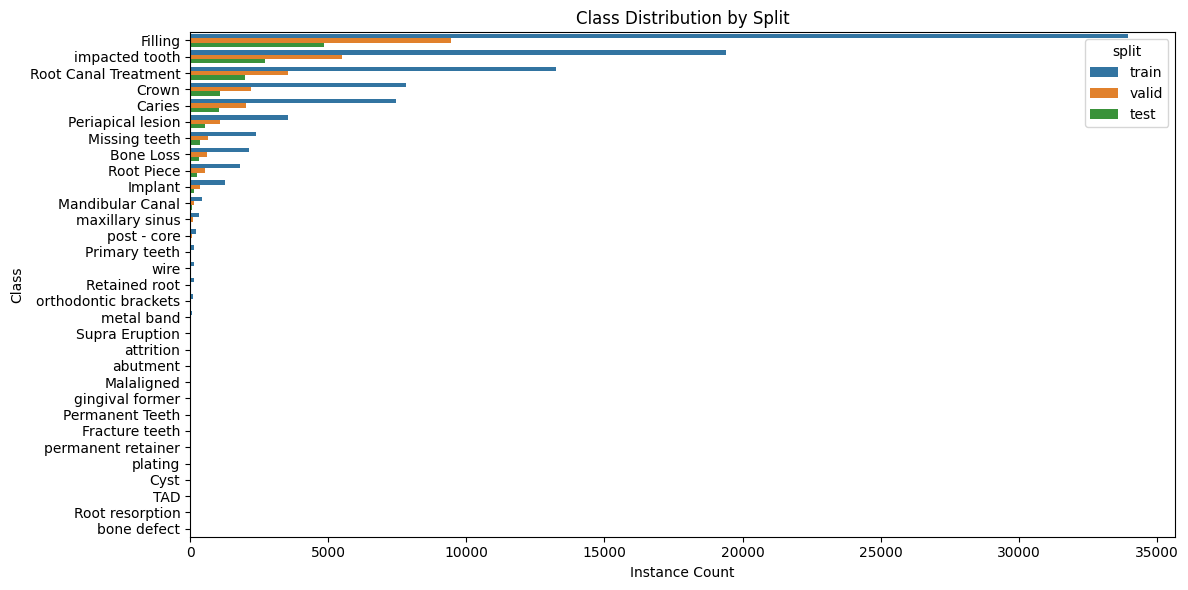

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

split_table = (df.groupby(["class_name", "split"]).size()
                 .unstack(fill_value=0)
                 .reindex(columns=SPLITS, fill_value=0))
split_table["total"] = split_table.sum(axis=1)
split_table = split_table.sort_values("total", ascending=False)
print(split_table)

plt.figure(figsize=(12, 6))
sns.countplot(data=df, y="class_name", hue="split",
              order=df["class_name"].value_counts().index)
plt.title("Class Distribution by Split")
plt.xlabel("Instance Count")
plt.ylabel("Class")
plt.tight_layout()
plt.show()

## 9. Images-per-class and background-image ratio
How many *images* (not boxes) contain each class, and what fraction of images across the whole dataset have zero annotations at all (true background frames).

In [11]:
all_files_per_split = {}
for split in SPLITS:
    img_dir = f"{WORK_DIR}/{split}/images"
    if os.path.isdir(img_dir):
        all_files_per_split[split] = glob.glob(f"{img_dir}/*.*")

rows = []
for cid, cname in class_map.items():
    n_images = sum(1 for split in SPLITS for classes in file_classes[split].values() if cid in classes)
    n_boxes = len(df[df["class_id"] == cid])
    rows.append({
        "class": cname,
        "images_containing": n_images,
        "total_boxes": n_boxes,
        "boxes_per_image": round(n_boxes / n_images, 2) if n_images else 0,
    })
print(pd.DataFrame(rows).to_string(index=False))

total_images = sum(len(v) for v in all_files_per_split.values())
annotated_files = {f for split in SPLITS for f in file_classes[split].keys() if file_classes[split][f]}
n_annotated = sum(1 for split in SPLITS for f, cls in file_classes[split].items() if cls)
n_background = total_images - n_annotated
print(f"\nTotal images       : {total_images}")
print(f"With >=1 annotation: {n_annotated}")
print(f"Background (empty) : {n_background} ({n_background/total_images*100:.1f}%)")

               class  images_containing  total_boxes  boxes_per_image
           Bone Loss               1467         3084             2.10
              Caries               3011        10546             3.50
               Crown               4027        11106             2.76
                Cyst                  5            5             1.00
             Filling               9797        48237             4.92
      Fracture teeth                 10           11             1.10
             Implant                605         1765             2.92
          Malaligned                 12           18             1.50
    Mandibular Canal                318          615             1.93
       Missing teeth               1625         3430             2.11
   Periapical lesion               2330         5189             2.23
     Permanent Teeth                  5           12             2.40
       Primary teeth                 47          228             4.85
       Retained root

## 10. Class co-occurrence matrix (within-image, train split)

                      Bone Loss  Caries  Crown  Cyst  Filling  Fracture teeth  Implant  Malaligned  Mandibular Canal  Missing teeth  Periapical lesion  Permanent Teeth  Primary teeth  Retained root  Root Canal Treatment  Root Piece  Root resorption  Supra Eruption  TAD  abutment  attrition  bone defect  gingival former  impacted tooth  maxillary sinus  metal band  orthodontic brackets  permanent retainer  plating  post - core  wire
Bone Loss                  1022     291    383     2      789               5       59           5                 0            179                202                0             10             22                   489          83                0              19    0         9         12            0                4             841                0          22                    17                   2        1           51    21
Caries                      291    2113    818     0     1564               5      136           3               123            

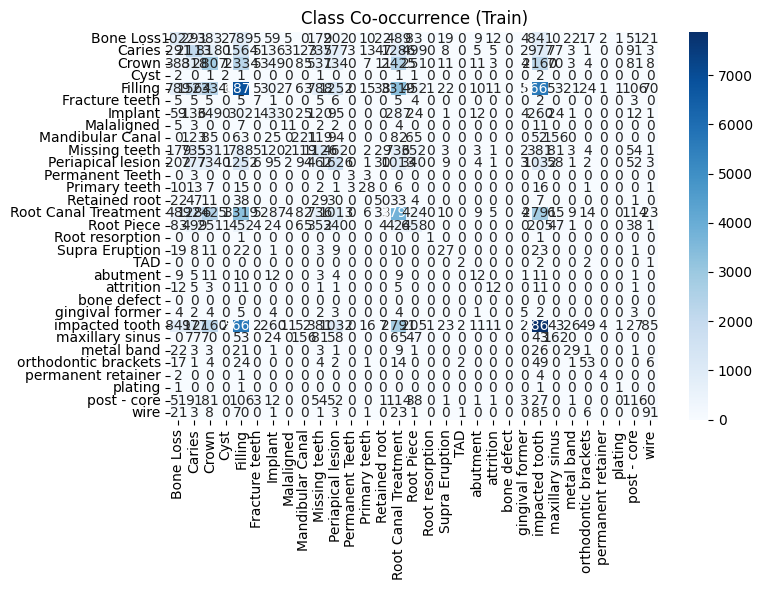

In [12]:
co_matrix = pd.DataFrame(0, index=class_map.values(), columns=class_map.values())
for classes in file_classes["train"].values():
    for c1 in classes:
        for c2 in classes:
            co_matrix.loc[class_map[c1], class_map[c2]] += 1
print(co_matrix.to_string())

plt.figure(figsize=(8, 6))
sns.heatmap(co_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Class Co-occurrence (Train)")
plt.tight_layout()
plt.show()

## 11. Box dimension / area / aspect ratio distributions per class

Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.


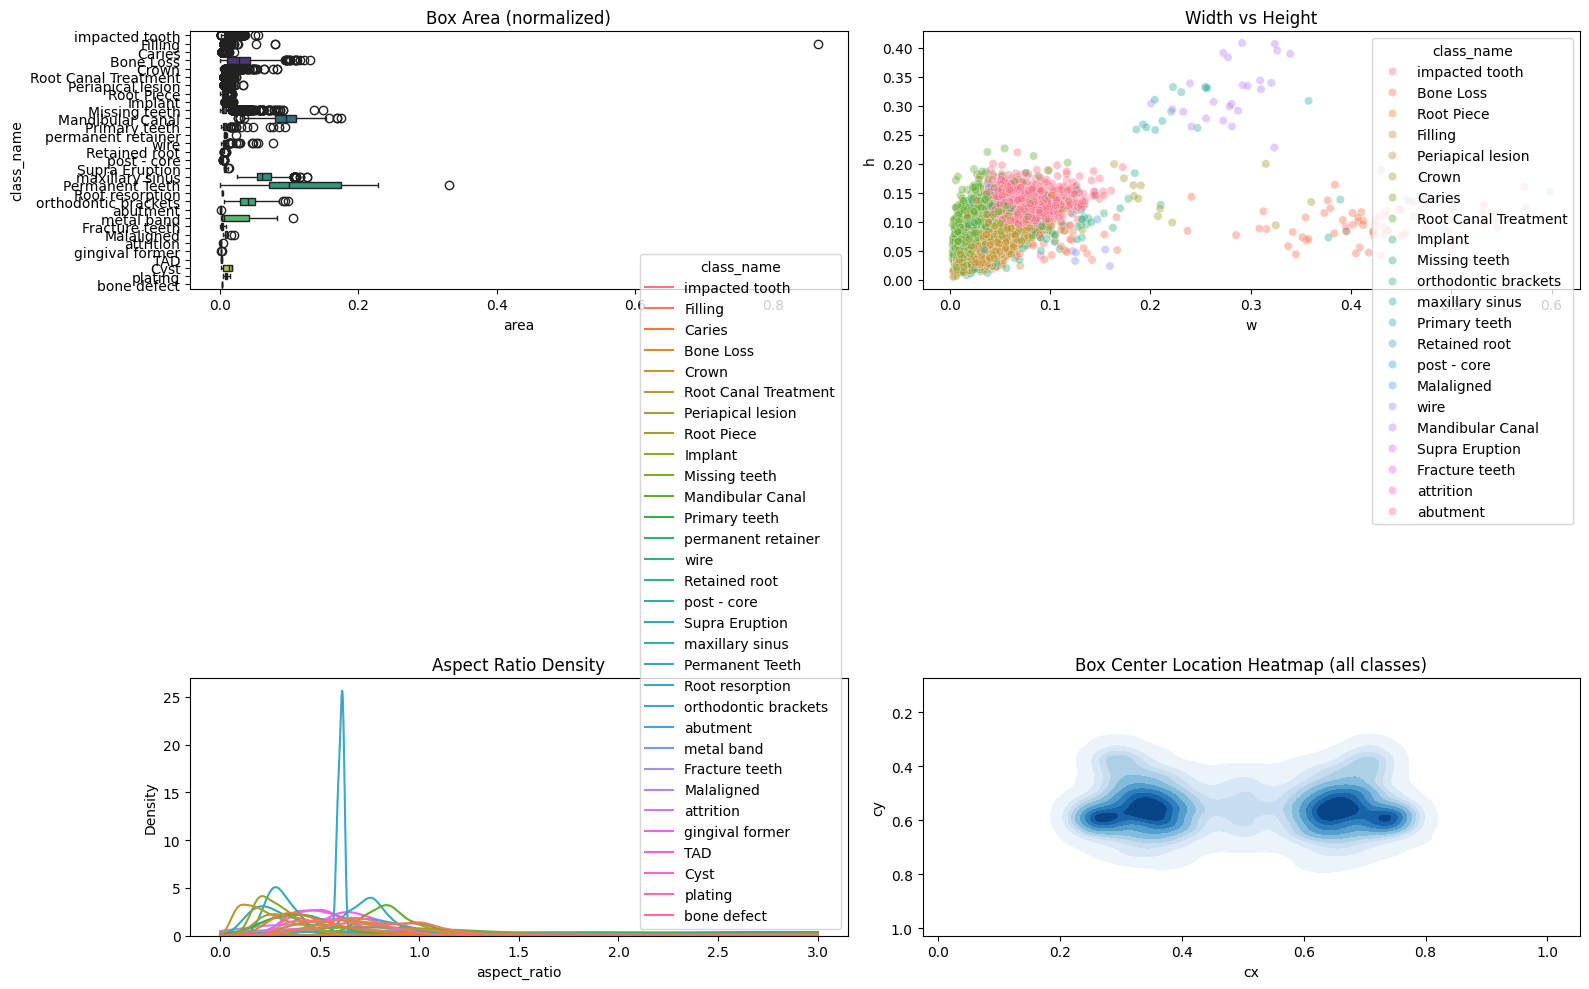

class_name            Bone Loss        Caries         Crown      Cyst  \
w            count  3084.000000  10546.000000  11106.000000  5.000000   
             mean      0.303446      0.021367      0.052318  0.064601   
             std       0.154348      0.015453      0.029182  0.028836   
             min       0.008134      0.003086      0.001005  0.028592   
             25%       0.137477      0.010853      0.035995  0.042067   
             50%       0.355198      0.016511      0.047258  0.075521   
             75%       0.426789      0.027119      0.058866  0.076823   
             max       0.670722      0.358323      0.490865  0.100000   
h            count  3084.000000  10546.000000  11106.000000  5.000000   
             mean      0.085869      0.043392      0.078010  0.141691   
             std       0.032903      0.018954      0.016475  0.071550   
             min       0.004688      0.004787      0.022283  0.043810   
             25%       0.062500      0.028846      

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

sns.boxplot(data=df, x="area", y="class_name", hue="class_name", legend=False,
            palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Box Area (normalized)")

sns.scatterplot(data=df.sample(min(5000, len(df))), x="w", y="h", hue="class_name",
                 alpha=0.4, ax=axes[0, 1])
axes[0, 1].set_title("Width vs Height")

sns.kdeplot(data=df, x="aspect_ratio", hue="class_name", common_norm=False,
            clip=(0, 3), ax=axes[1, 0])
axes[1, 0].set_title("Aspect Ratio Density")

sns.kdeplot(data=df, x="cx", y="cy", cmap="Blues", fill=True, thresh=0.05, ax=axes[1, 1])
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Box Center Location Heatmap (all classes)")

plt.tight_layout()
plt.show()

print(df.groupby("class_name")[["w", "h", "area", "aspect_ratio"]].describe().T)

## 12. Per-class center-location heatmaps
Separate heatmaps per class — useful for spotting the kind of positional pattern that flagged the 'impacted tooth' central-arch issue last time, without deciding anything yet.

KDE cannot be estimated (0 variance or perfect covariance). Pass `warn_singular=False` to disable this warning.


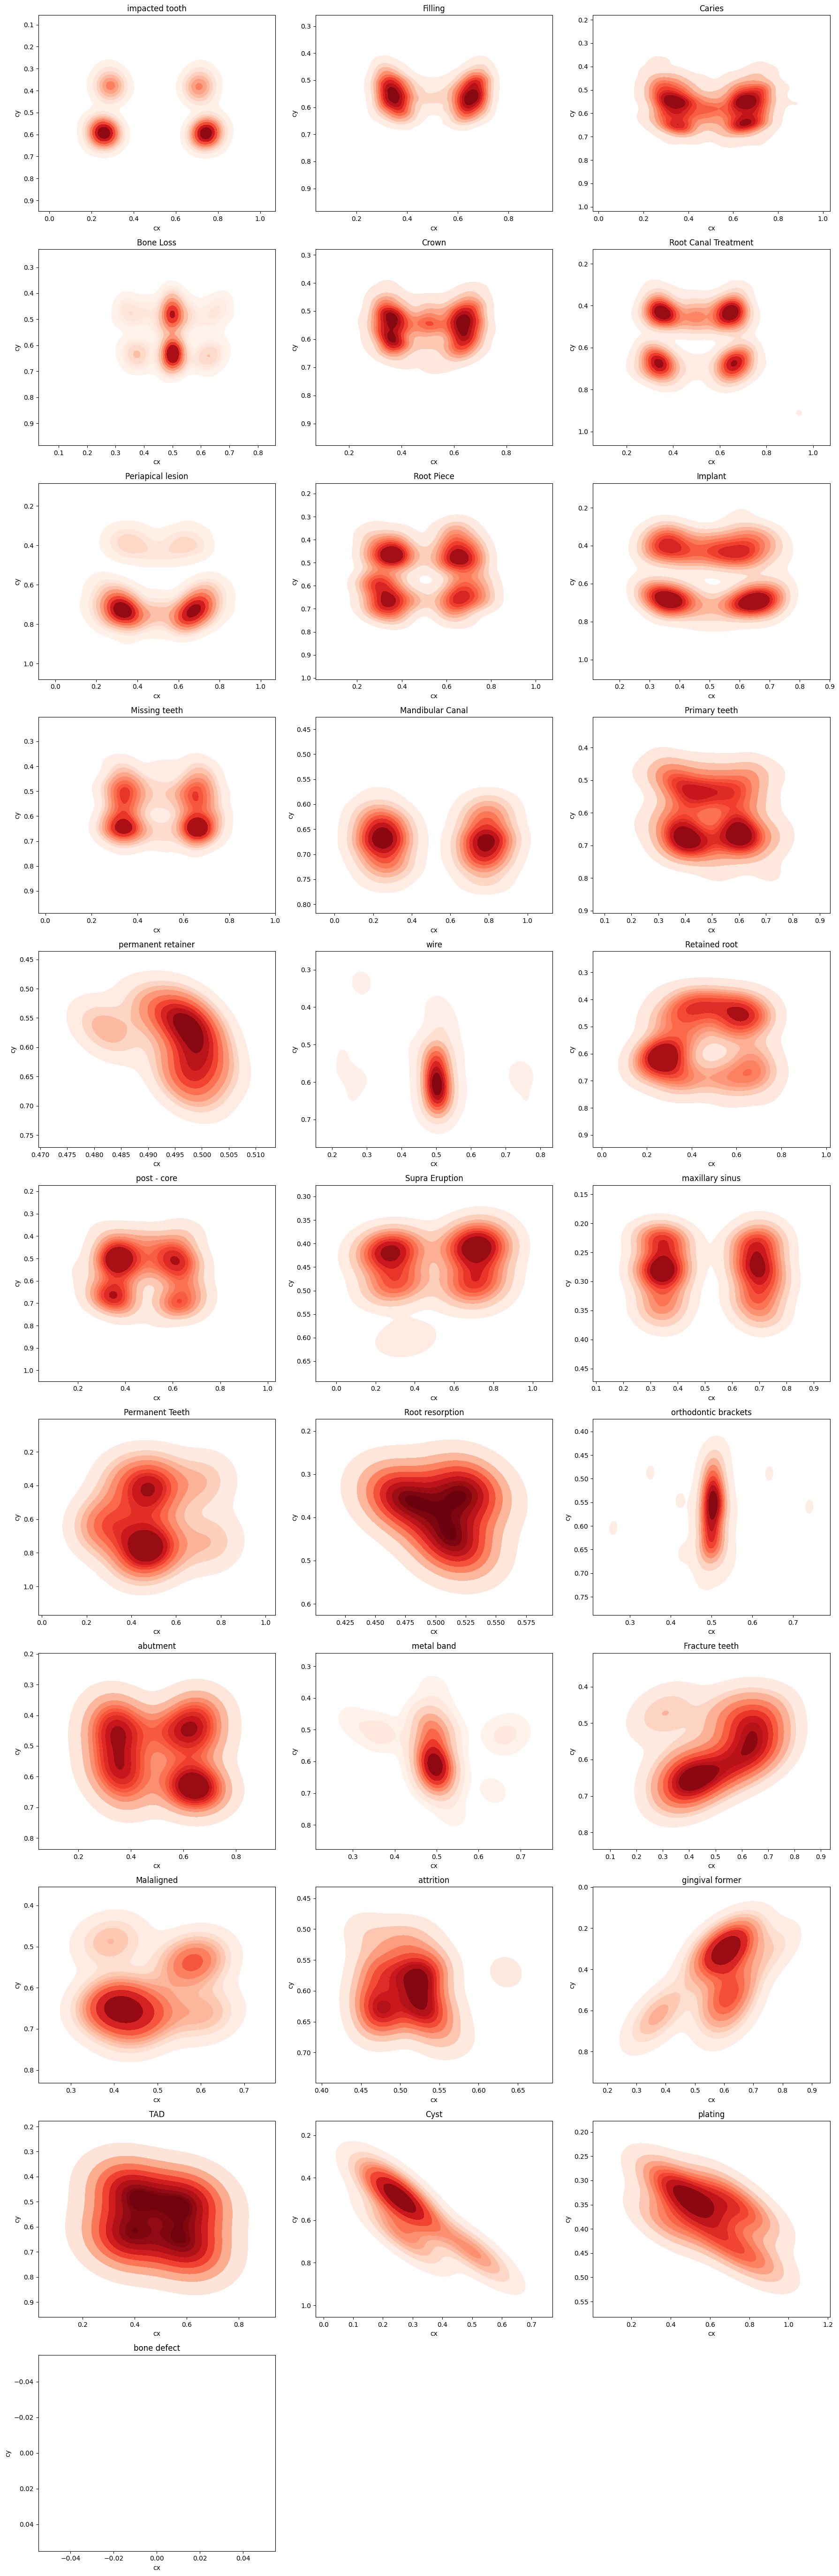

In [14]:
classes_present = df["class_name"].unique()
n = len(classes_present)
cols = 3
rows_n = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_n, cols, figsize=(6 * cols, 5 * rows_n))
axes = axes.flatten()

for i, cname in enumerate(classes_present):
    sub = df[df["class_name"] == cname]
    sns.kdeplot(data=sub, x="cx", y="cy", cmap="Reds", fill=True, thresh=0.05, ax=axes[i])
    axes[i].invert_yaxis()
    axes[i].set_title(cname)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## 13. Box density per image (histogram)

        count      mean       std  min  25%  50%   75%   max
split                                                       
test   1369.0  9.848795  7.573504  1.0  4.0  8.0  13.0  50.0
train  9577.0  9.891720  7.662925  1.0  4.0  8.0  13.0  56.0
valid  2739.0  9.681271  7.362292  1.0  4.0  8.0  13.0  60.0


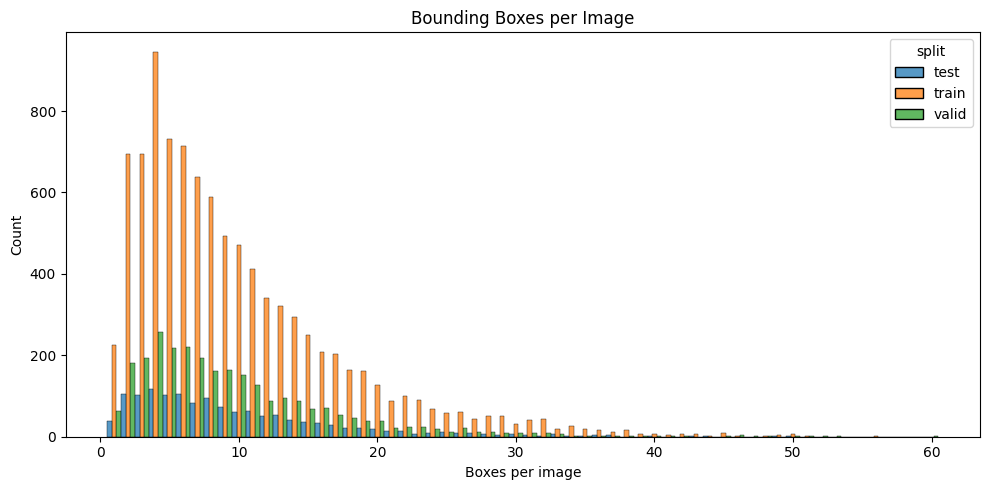

In [15]:
density = df.groupby(["split", "file"]).size().reset_index(name="box_count")

print(density.groupby("split")["box_count"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(data=density, x="box_count", hue="split", discrete=True, multiple="dodge")
plt.title("Bounding Boxes per Image")
plt.xlabel("Boxes per image")
plt.tight_layout()
plt.show()

## 14. IQR outlier report per class (report only — nothing removed)

In [16]:
def iqr_bounds(group):
    q1, q3 = group["area"].quantile([0.25, 0.75])
    iqr = q3 - q1
    return max(0.0001, q1 - 1.5 * iqr), q3 + 1.5 * iqr

outlier_rows = []
for cname, group in df.groupby("class_name"):
    lo, hi = iqr_bounds(group)
    n_low = (group["area"] < lo).sum()
    n_high = (group["area"] > hi).sum()
    outlier_rows.append({
        "class": cname, "n_boxes": len(group),
        "lower_bound": round(lo, 5), "upper_bound": round(hi, 5),
        "below_lower": int(n_low), "above_upper": int(n_high),
        "pct_flagged": round((n_low + n_high) / len(group) * 100, 2),
    })
print(pd.DataFrame(outlier_rows).to_string(index=False))

               class  n_boxes  lower_bound  upper_bound  below_lower  above_upper  pct_flagged
           Bone Loss     3084      0.00010      0.09382            0           18         0.58
              Caries    10546      0.00010      0.00305          153          892         9.91
               Crown    11106      0.00010      0.00779            2          730         6.59
                Cyst        5      0.00010      0.03646            0            0         0.00
             Filling    48237      0.00010      0.00615          152         1248         2.90
      Fracture teeth       11      0.00010      0.00907            0            0         0.00
             Implant     1765      0.00010      0.00675            0          113         6.40
          Malaligned       18      0.00313      0.01509            0            2        11.11
    Mandibular Canal      615      0.03469      0.15549            5            4         1.46
       Missing teeth     3430      0.00010      0.

## 15. Within-image overlap / duplicate-box audit (IoU)

In [17]:
def compute_iou(box1, box2):
    b1x1, b1x2 = box1[0] - box1[2] / 2, box1[0] + box1[2] / 2
    b1y1, b1y2 = box1[1] - box1[3] / 2, box1[1] + box1[3] / 2
    b2x1, b2x2 = box2[0] - box2[2] / 2, box2[0] + box2[2] / 2
    b2y1, b2y2 = box2[1] - box2[3] / 2, box2[1] + box2[3] / 2
    ix1, iy1 = max(b1x1, b2x1), max(b1y1, b2y1)
    ix2, iy2 = min(b1x2, b2x2), min(b1y2, b2y2)
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    a1, a2 = box1[2] * box1[3], box2[2] * box2[3]
    return inter / (a1 + a2 - inter + 1e-6)

same_class_dupes, cross_class_overlaps, affected = 0, 0, set()

for split in SPLITS:
    lbl_dir = f"{WORK_DIR}/{split}/labels"
    if not os.path.isdir(lbl_dir):
        continue
    for lbl_path in glob.glob(f"{lbl_dir}/*.txt"):
        with open(lbl_path, "r") as f:
            lines = [l.strip().split() for l in f if l.strip()]
        boxes = []
        for parts in lines:
            if len(parts) != 5:
                continue
            cls_id = int(parts[0])
            cx, cy, w, h = map(float, parts[1:])
            boxes.append((cls_id, (cx, cy, w, h)))
        for i in range(len(boxes)):
            for j in range(i + 1, len(boxes)):
                c1, b1 = boxes[i]
                c2, b2 = boxes[j]
                if compute_iou(b1, b2) > 0.6:
                    affected.add(lbl_path)
                    if c1 == c2:
                        same_class_dupes += 1
                    else:
                        cross_class_overlaps += 1

print(f"Images with high-overlap boxes (IoU > 0.6): {len(affected)}")
print(f"Same-class duplicate boxes                 : {same_class_dupes}")
print(f"Cross-class overlapping boxes               : {cross_class_overlaps}")

Images with high-overlap boxes (IoU > 0.6): 106
Same-class duplicate boxes                 : 86
Cross-class overlapping boxes               : 35


## 16. Image resolution / aspect ratio consistency check

split           test   train   valid
width  count  1369.0  9577.0  2739.0
       mean    640.0   640.0   640.0
       std       0.0     0.0     0.0
       min     640.0   640.0   640.0
       25%     640.0   640.0   640.0
       50%     640.0   640.0   640.0
       75%     640.0   640.0   640.0
       max     640.0   640.0   640.0
height count  1369.0  9577.0  2739.0
       mean    640.0   640.0   640.0
       std       0.0     0.0     0.0
       min     640.0   640.0   640.0
       25%     640.0   640.0   640.0
       50%     640.0   640.0   640.0
       75%     640.0   640.0   640.0
       max     640.0   640.0   640.0
aspect count  1369.0  9577.0  2739.0
       mean      1.0     1.0     1.0
       std       0.0     0.0     0.0
       min       1.0     1.0     1.0
       25%       1.0     1.0     1.0
       50%       1.0     1.0     1.0
       75%       1.0     1.0     1.0
       max       1.0     1.0     1.0


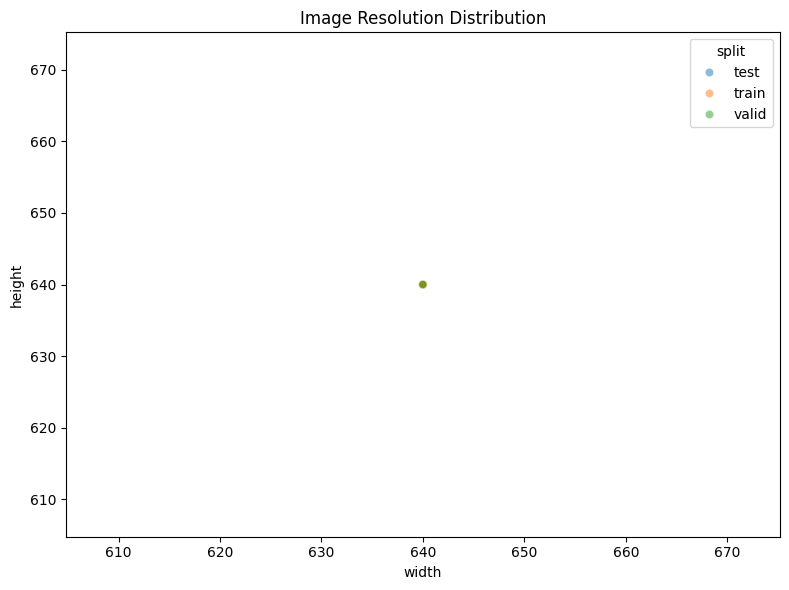

In [18]:
res_records = []
for split in SPLITS:
    img_dir = f"{WORK_DIR}/{split}/images"
    if not os.path.isdir(img_dir):
        continue
    for img_path in glob.glob(f"{img_dir}/*.*"):
        img = cv2.imread(img_path)
        if img is None:
            continue
        h, w = img.shape[:2]
        res_records.append({"split": split, "width": w, "height": h, "aspect": w / h})

res_df = pd.DataFrame(res_records)
print(res_df.groupby("split")[["width", "height", "aspect"]].describe().T)

plt.figure(figsize=(8, 6))
sns.scatterplot(data=res_df.sample(min(2000, len(res_df))), x="width", y="height", hue="split", alpha=0.5)
plt.title("Image Resolution Distribution")
plt.tight_layout()
plt.show()

## 17. Stratified visual audit sample (per class, before any cleaning)
Same approach as Task A — pull a handful of images per class and actually look at them before deciding on any thresholds.

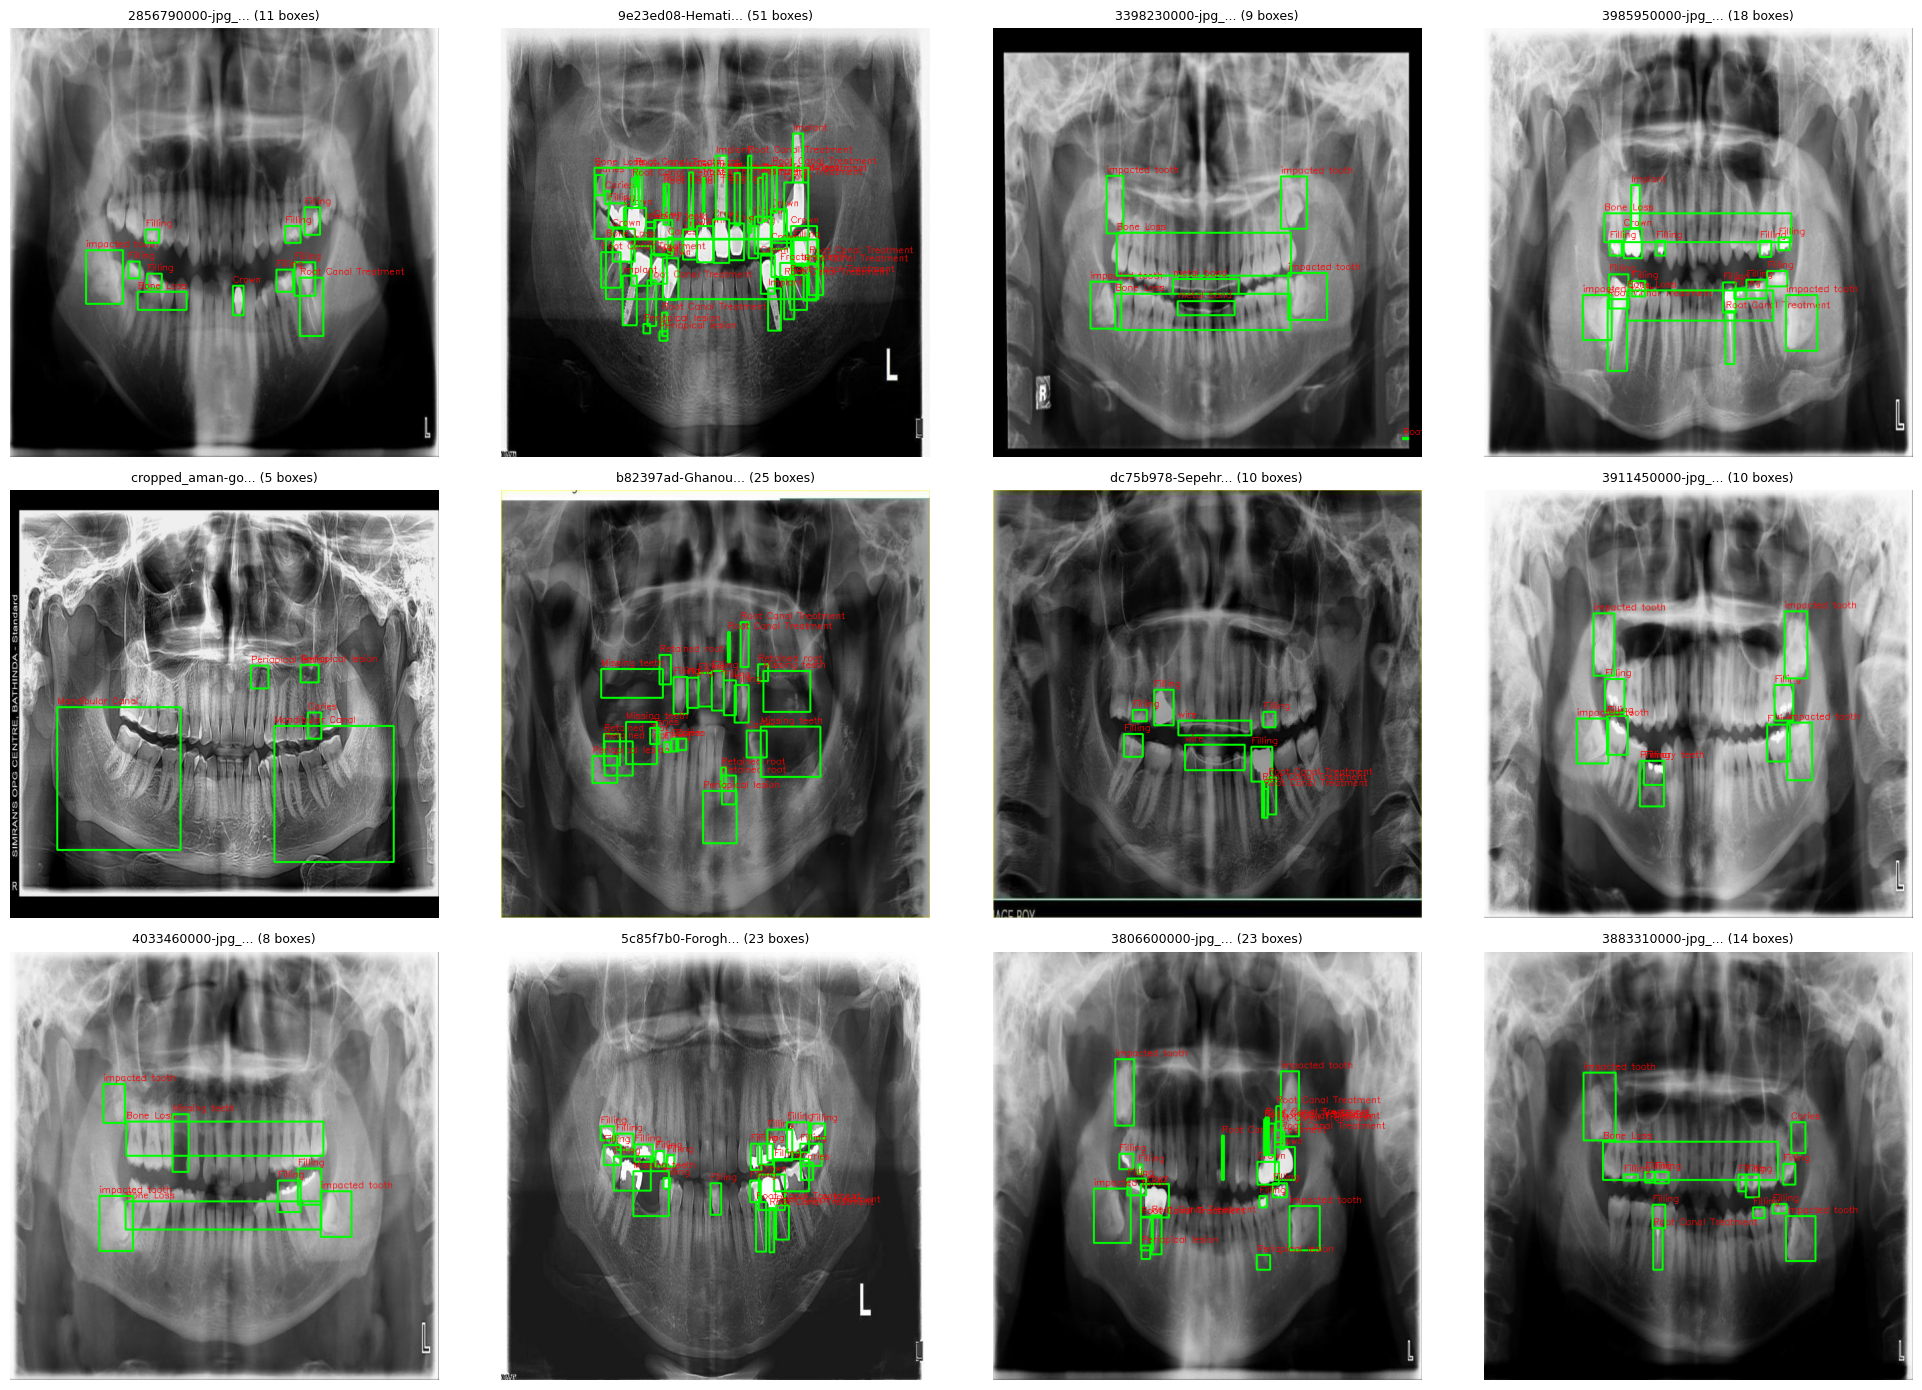

In [19]:
import random

random.seed(42)
audit_files = set()
for cid in class_map.keys():
    matches = [f for f, classes in file_classes["train"].items() if cid in classes]
    audit_files.update(random.sample(matches, min(8, len(matches))))

audit_list = list(audit_files)[:12]

fig, axes = plt.subplots(3, 4, figsize=(20, 14))
axes = axes.flatten()

for idx, fname in enumerate(audit_list):
    matches = glob.glob(f"{WORK_DIR}/train/images/{os.path.splitext(fname)[0]}.*")
    if not matches:
        continue
    img = cv2.imread(matches[0])
    if img is None:
        continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    lbl_path = f"{WORK_DIR}/train/labels/{fname}"
    with open(lbl_path, "r") as f:
        lines = [l.strip().split() for l in f if l.strip()]

    for parts in lines:
        if len(parts) != 5:
            continue
        cls_id = int(parts[0])
        cx, cy, bw, bh = map(float, parts[1:])
        xmin, ymin = int((cx - bw / 2) * w), int((cy - bh / 2) * h)
        xmax, ymax = int((cx + bw / 2) * w), int((cy + bh / 2) * h)
        cv2.rectangle(img, (xmin, ymin), (xmax, ymax), (0, 255, 0), 2)
        cv2.putText(img, class_map.get(cls_id, str(cls_id)), (xmin, max(ymin - 5, 12)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 0, 0), 1)

    axes[idx].imshow(img)
    axes[idx].axis("off")
    axes[idx].set_title(f"{fname[:15]}... ({len(lines)} boxes)", fontsize=9)

for j in range(idx + 1, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## 18. Summary — review before writing any cleaning logic
Everything above is diagnostic only. Once you've looked through class balance, box geometry, the duplicate/leakage report, and the visual audit, we pick actual thresholds and a cleaning strategy (per-box capping instead of whole-image deletion, since that was the main critique of the Task A cleaning pass) in a follow-up notebook — same copy-before-you-cut approach as `dataset_cleaned` in Task A.

In [20]:
import os
import glob
import shutil
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

try:
    import imagehash
except ImportError:
    os.system("pip install imagehash")
    import imagehash

from tqdm import tqdm

# ==========================================
# UPDATED CONFIGURATION FOR YOUR FILE STRUCTURE
# ==========================================

# 1. FIXED PATHS (Pointing to task_b_working directory and 'valid' split)
DATASET_SPLITS = {
    "train": {
        "images": "./task_b_working/train/images",
        "labels": "./task_b_working/train/labels"
    },
    "val": {
        "images": "./task_b_working/valid/images",  # Note: 'valid', not 'val'
        "labels": "./task_b_working/valid/labels"
    },
    "test": {
        "images": "./task_b_working/test/images",
        "labels": "./task_b_working/test/labels"
    }
}

# 2. EXACT ORIGINAL CLASS IDs FOR YOUR 4 TARGET CLASSES
# (Raw dataset mapping from dental-x-ray-panoramic OPG taxonomy)
CLASS_MAPPING = {
    18: (0, "impacted tooth"),
    30: (1, "Root Canal Treatment"),
    11: (2, "Crown"),
    7:  (3, "Caries")
}

TARGET_NAMES = [cls_info[1] for cls_info in CLASS_MAPPING.values()]
CLEAN_DIR = "./clean_eda_4classes"

os.makedirs(f"{CLEAN_DIR}/plots", exist_ok=True)
for split in DATASET_SPLITS.keys():
    os.makedirs(f"{CLEAN_DIR}/{split}/images", exist_ok=True)
    os.makedirs(f"{CLEAN_DIR}/{split}/labels", exist_ok=True)


# ==========================================
# 2. FILTERING DATASET WITH DIAGNOSTICS
# ==========================================
print("--- [STEP 1] Filtering Dataset to Target 4 Classes ---")

filtered_records = []
found_raw_class_ids = set()

for split, paths in DATASET_SPLITS.items():
    label_dir = os.path.abspath(paths["labels"])
    image_dir = os.path.abspath(paths["images"])

    label_files = glob.glob(os.path.join(label_dir, "*.txt"))
    print(f"Found {len(label_files)} label files in split '{split}' at: {label_dir}")

    for lbl_path in tqdm(label_files, desc=f"Filtering {split}"):
        file_name = os.path.basename(lbl_path)
        img_basename = os.path.splitext(file_name)[0]

        # Resolve matching image
        img_path = None
        for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.PNG']:
            possible_path = os.path.join(image_dir, img_basename + ext)
            if os.path.exists(possible_path):
                img_path = possible_path
                break

        if not img_path:
            continue

        valid_lines = []
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue

                raw_cls_id = int(parts[0])
                found_raw_class_ids.add(raw_cls_id)

                if raw_cls_id in CLASS_MAPPING:
                    new_cls_id, cls_name = CLASS_MAPPING[raw_cls_id]
                    x_c, y_c, w, h = map(float, parts[1:5])
                    valid_lines.append(f"{new_cls_id} {x_c} {y_c} {w} {h}\n")

                    filtered_records.append({
                        "split": split,
                        "image_name": os.path.basename(img_path),
                        "img_path": img_path,
                        "class_id": new_cls_id,
                        "class_name": cls_name,
                        "x_center": x_c,
                        "y_center": y_c,
                        "width": w,
                        "height": h,
                        "area": w * h,
                        "aspect_ratio": w / (h + 1e-6)
                    })

        if valid_lines:
            new_lbl_path = os.path.join(CLEAN_DIR, split, "labels", file_name)
            new_img_path = os.path.join(CLEAN_DIR, split, "images", os.path.basename(img_path))

            with open(new_lbl_path, 'w') as f:
                f.writelines(valid_lines)
            shutil.copy2(img_path, new_img_path)

# Safe DataFrame Construction
if filtered_records:
    df_boxes = pd.DataFrame(filtered_records)
    print(f"\n✅ Extraction complete! Filtered {len(df_boxes)} instances across 4 classes.\n")
else:
    df_boxes = pd.DataFrame(columns=[
        "split", "image_name", "img_path", "class_id", "class_name",
        "x_center", "y_center", "width", "height", "area", "aspect_ratio"
    ])
    print(f"\n⚠️ WARNING: 0 matching instances found!")
    print(f"Raw Class IDs detected in your dataset files: {sorted(list(found_raw_class_ids))}")
    print("Please check if CLASS_MAPPING keys match these raw class IDs or fix path settings in DATASET_SPLITS.\n")


# ==========================================
# 3. SAFE LEAKAGE CHECK (HANDLES EMPTY DFs)
# ==========================================
print("--- [STEP 2] Checking for Data Leakage Across Splits ---")

if not df_boxes.empty:
    image_records = df_boxes[['split', 'img_path']].drop_duplicates()
    hashes_md5 = {}
    hashes_phash = {}
    leakage_records = []

    for _, row in tqdm(image_records.iterrows(), total=len(image_records), desc="Hashing Images"):
        path = row['img_path']
        split = row['split']

        with open(path, 'rb') as f:
            md5_val = hashlib.md5(f.read()).hexdigest()

        try:
            with Image.open(path) as img:
                phash_val = str(imagehash.phash(img))
        except Exception:
            phash_val = None

        if md5_val in hashes_md5:
            orig_split, orig_path = hashes_md5[md5_val]
            if orig_split != split:
                leakage_records.append({
                    "type": "Exact MD5 Duplicate",
                    "train_split": orig_split,
                    "target_split": split,
                    "image": os.path.basename(path)
                })
        else:
            hashes_md5[md5_val] = (split, path)

        if phash_val:
            if phash_val in hashes_phash:
                orig_split, orig_path = hashes_phash[phash_val]
                if orig_split != split:
                    leakage_records.append({
                        "type": "Perceptual Duplicate (pHash)",
                        "train_split": orig_split,
                        "target_split": split,
                        "image": os.path.basename(path)
                    })
            else:
                hashes_phash[phash_val] = (split, path)

    df_leakage = pd.DataFrame(leakage_records)
    if not df_leakage.empty:
        print(f"⚠️ LEAKAGE DETECTED! Found {len(df_leakage)} leaked instances across splits.")
        df_leakage.to_csv(f"{CLEAN_DIR}/leakage_report.csv", index=False)
    else:
        print("✅ Zero cross-split leakage detected among the target dataset.")
else:
    print("Skipping leakage analysis due to empty filtered dataframe.")


# ==========================================
# 4. DIAGNOSTIC PLOTS
# ==========================================
if not df_boxes.empty:
    print("--- [STEP 3] Generating Visualizations ---")

    # 1. Class Distribution
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df_boxes, y='class_name', hue='split', palette='viridis')
    plt.title("Class Counts Across Splits")
    plt.tight_layout()
    plt.savefig(f"{CLEAN_DIR}/plots/class_distribution.png")
    plt.close()

    # 2. Geometry Metrics
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(data=df_boxes, x='area', y='class_name', ax=axes[0], palette='crest')
    axes[0].set_title("Normalized Area")
    sns.boxplot(data=df_boxes, x='aspect_ratio', y='class_name', ax=axes[1], palette='crest')
    axes[1].set_title("Aspect Ratio")
    axes[1].set_xlim(0, 4)
    plt.tight_layout()
    plt.savefig(f"{CLEAN_DIR}/plots/box_geometry.png")
    plt.close()

    print(f"EDA Complete! Output directory: '{CLEAN_DIR}/'")

--- [STEP 1] Filtering Dataset to Target 4 Classes ---
Found 9577 label files in split 'train' at: /content/task_b_working/train/labels


Filtering train: 100%|██████████| 9577/9577 [00:00<00:00, 22823.86it/s]


Found 2739 label files in split 'val' at: /content/task_b_working/valid/labels


Filtering val: 100%|██████████| 2739/2739 [00:00<00:00, 27761.81it/s]


Found 1369 label files in split 'test' at: /content/task_b_working/test/labels


...


✅ Extraction complete! Filtered 260 instances across 4 classes.

--- [STEP 2] Checking for Data Leakage Across Splits ---


Hashing Images: 100%|██████████| 152/152 [00:00<00:00, 167.20it/s]


Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



✅ Zero cross-split leakage detected among the target dataset.
--- [STEP 3] Generating Visualizations ---




Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.



EDA Complete! Output directory: './clean_eda_4classes/'


In [21]:
import yaml

# Load dataset YAML configuration
yaml_path = "./dental-x-ray-panoramic-2/data.yaml"  # adjust path if needed

with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print("--- RAW DATASET CLASS NAMES & IDs ---")
for idx, name in enumerate(data_config.get("names", [])):
    print(f"ID {idx}: {name}")

--- RAW DATASET CLASS NAMES & IDs ---
ID 0: Bone Loss
ID 1: Caries
ID 2: Crown
ID 3: Cyst
ID 4: Filling
ID 5: Fracture teeth
ID 6: Implant
ID 7: Malaligned
ID 8: Mandibular Canal
ID 9: Missing teeth
ID 10: Periapical lesion
ID 11: Permanent Teeth
ID 12: Primary teeth
ID 13: Retained root
ID 14: Root Canal Treatment
ID 15: Root Piece
ID 16: Root resorption
ID 17: Supra Eruption
ID 18: TAD
ID 19: abutment
ID 20: attrition
ID 21: bone defect
ID 22: gingival former
ID 23: impacted tooth
ID 24: maxillary sinus
ID 25: metal band
ID 26: orthodontic brackets
ID 27: permanent retainer
ID 28: plating
ID 29: post - core
ID 30: wire


In [22]:
import shutil

# Remove previous partial run directory if it exists
shutil.rmtree("./clean_eda_4classes", ignore_errors=True)
print("Cleared old filtered directory. Ready for fresh 4-class extraction!")

Cleared old filtered directory. Ready for fresh 4-class extraction!


In [23]:
import os
import glob
import shutil
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

try:
    import imagehash
except ImportError:
    os.system("pip install imagehash")
    import imagehash

# ==========================================
# 1. EXACT CONFIGURATION FOR YOUR DATASET
# ==========================================
DATASET_SPLITS = {
    "train": {"images": "./task_b_working/train/images", "labels": "./task_b_working/train/labels"},
    "val":   {"images": "./task_b_working/valid/images", "labels": "./task_b_working/valid/labels"},
    "test":  {"images": "./task_b_working/test/images",  "labels": "./task_b_working/test/labels"}
}

# Corrected Raw Class IDs based on your raw data output:
CLASS_MAPPING = {
    23: (0, "impacted tooth"),        # ID 23
    14: (1, "Root Canal Treatment"), # ID 14
    2:  (2, "Crown"),                # ID 2
    1:  (3, "Caries")                # ID 1
}

TARGET_NAMES = [v[1] for v in CLASS_MAPPING.values()]
CLEAN_DIR = "./clean_eda_4classes"

os.makedirs(f"{CLEAN_DIR}/plots", exist_ok=True)
for split in DATASET_SPLITS.keys():
    os.makedirs(f"{CLEAN_DIR}/{split}/images", exist_ok=True)
    os.makedirs(f"{CLEAN_DIR}/{split}/labels", exist_ok=True)


# ==========================================
# 2. FILTER & EXTRACT
# ==========================================
print("--- [STEP 1] Extracting Full 4-Class Dataset ---")

filtered_records = []
for split, paths in DATASET_SPLITS.items():
    label_files = glob.glob(os.path.join(paths["labels"], "*.txt"))

    for lbl_path in tqdm(label_files, desc=f"Filtering {split}"):
        file_name = os.path.basename(lbl_path)
        img_basename = os.path.splitext(file_name)[0]

        img_path = None
        for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.PNG']:
            possible = os.path.join(paths["images"], img_basename + ext)
            if os.path.exists(possible):
                img_path = possible
                break
        if not img_path:
            continue

        valid_lines = []
        with open(lbl_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if not parts:
                    continue
                raw_cls_id = int(parts[0])

                if raw_cls_id in CLASS_MAPPING:
                    new_cls_id, cls_name = CLASS_MAPPING[raw_cls_id]
                    x_c, y_c, w, h = map(float, parts[1:5])
                    valid_lines.append(f"{new_cls_id} {x_c} {y_c} {w} {h}\n")

                    filtered_records.append({
                        "split": split,
                        "image_name": os.path.basename(img_path),
                        "img_path": img_path,
                        "class_id": new_cls_id,
                        "class_name": cls_name,
                        "x_center": x_c,
                        "y_center": y_c,
                        "width": w,
                        "height": h,
                        "area": w * h,
                        "aspect_ratio": w / (h + 1e-6)
                    })

        if valid_lines:
            new_lbl_path = os.path.join(CLEAN_DIR, split, "labels", file_name)
            new_img_path = os.path.join(CLEAN_DIR, split, "images", os.path.basename(img_path))

            with open(new_lbl_path, 'w') as f:
                f.writelines(valid_lines)
            shutil.copy2(img_path, new_img_path)

df_boxes = pd.DataFrame(filtered_records)
print(f"\n Extraction Complete! Filtered {len(df_boxes)} total instances across 4 classes.\n")


# ==========================================
# 3. FULL LEAKAGE CHECK
# ==========================================
print("--- [STEP 2] Running Leakage Analysis Across Splits ---")

if not df_boxes.empty:
    image_records = df_boxes[['split', 'img_path']].drop_duplicates()
    hashes_md5, hashes_phash, leakage_records = {}, {}, []

    for _, row in tqdm(image_records.iterrows(), total=len(image_records), desc="Hashing Images"):
        path, split = row['img_path'], row['split']

        with open(path, 'rb') as f:
            md5_val = hashlib.md5(f.read()).hexdigest()

        try:
            with Image.open(path) as img:
                phash_val = str(imagehash.phash(img))
        except Exception:
            phash_val = None

        # Check MD5
        if md5_val in hashes_md5:
            orig_split, _ = hashes_md5[md5_val]
            if orig_split != split:
                leakage_records.append({"type": "Exact MD5 Duplicate", "orig_split": orig_split, "leak_split": split, "image": os.path.basename(path)})
        else:
            hashes_md5[md5_val] = (split, path)

        # Check pHash
        if phash_val:
            if phash_val in hashes_phash:
                orig_split, _ = hashes_phash[phash_val]
                if orig_split != split:
                    leakage_records.append({"type": "Perceptual Duplicate (pHash)", "orig_split": orig_split, "leak_split": split, "image": os.path.basename(path)})
            else:
                hashes_phash[phash_val] = (split, path)

    df_leakage = pd.DataFrame(leakage_records)
    if not df_leakage.empty:
        print(f" LEAKAGE DETECTED! Found {len(df_leakage)} leaked image instances across splits.")
        df_leakage.to_csv(f"{CLEAN_DIR}/leakage_report.csv", index=False)
    else:
        print(" Zero cross-split leakage detected across these images.")


# ==========================================
# 4. DIAGNOSTIC EDA PLOTS
# ==========================================
if not df_boxes.empty:
    print("--- [STEP 3] Generating Visualizations ---")

    # 1. Instance Distribution Per Split
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df_boxes, y='class_name', hue='split', order=TARGET_NAMES, palette='viridis')
    plt.title("Class Instance Count Across Splits")
    plt.xlabel("Count")
    plt.ylabel("Class")
    plt.tight_layout()
    plt.savefig(f"{CLEAN_DIR}/plots/class_distribution.png", dpi=300)
    plt.close()

    # 2. Geometry Metrics (Area & Aspect Ratio)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.boxplot(data=df_boxes, x='area', y='class_name', hue='class_name', ax=axes[0], palette='crest', legend=False)
    axes[0].set_title("Normalized Box Area (Width * Height)")

    sns.boxplot(data=df_boxes, x='aspect_ratio', y='class_name', hue='class_name', ax=axes[1], palette='crest', legend=False)
    axes[1].set_title("Aspect Ratio (Width / Height)")
    axes[1].set_xlim(0, 4)

    plt.tight_layout()
    plt.savefig(f"{CLEAN_DIR}/plots/box_geometry.png", dpi=300)
    plt.close()

    # 3. Class Co-occurrence Heatmap
    img_class_matrix = pd.crosstab(df_boxes['image_name'], df_boxes['class_name'])
    co_occurrence = img_class_matrix.T.dot(img_class_matrix)

    plt.figure(figsize=(8, 6))
    sns.heatmap(co_occurrence, annot=True, fmt='d', cmap='Blues', square=True)
    plt.title("Class Co-Occurrence Matrix (Per Image)")
    plt.tight_layout()
    plt.savefig(f"{CLEAN_DIR}/plots/class_cooccurrence.png", dpi=300)
    plt.close()

    print(f"EDA Complete! Output directory and plots saved in '{CLEAN_DIR}/'.")

--- [STEP 1] Extracting Full 4-Class Dataset ---


Filtering test: 100%|██████████| 1369/1369 [00:00<00:00, 1876.92it/s]



 Extraction Complete! Filtered 68023 total instances across 4 classes.

--- [STEP 2] Running Leakage Analysis Across Splits ---


Hashing Images: 100%|██████████| 13303/13303 [00:59<00:00, 221.83it/s]


 LEAKAGE DETECTED! Found 2857 leaked image instances across splits.
--- [STEP 3] Generating Visualizations ---
EDA Complete! Output directory and plots saved in './clean_eda_4classes/'.


In [24]:
import os
import glob
import shutil
import hashlib
import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
from collections import defaultdict
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import imagehash
except ImportError:
    os.system("pip install imagehash")
    import imagehash

# ==========================================
# 1. CONFIGURATION & SETUP
# ==========================================
INPUT_DIR = "./clean_eda_4classes"
OUTPUT_DIR = "./clean_deduped_4classes"

# Clean target directories
shutil.rmtree(OUTPUT_DIR, ignore_errors=True)
for split in ["train", "val", "test"]:
    os.makedirs(f"{OUTPUT_DIR}/{split}/images", exist_ok=True)
    os.makedirs(f"{OUTPUT_DIR}/{split}/labels", exist_ok=True)

# Map target names back to YOLO IDs (0..3)
CLASS_NAMES = {0: "impacted tooth", 1: "Root Canal Treatment", 2: "Crown", 3: "Caries"}

# ==========================================
# 2. COLLECT ALL IMAGES & EXTRACT HASHES
# ==========================================
print("--- [STEP 1] Hashing All Images Across Existing Splits ---")

image_paths = []
for split in ["train", "val", "test"]:
    imgs = glob.glob(f"{INPUT_DIR}/{split}/images/*.[jJ][pP][gG]") + \
           glob.glob(f"{INPUT_DIR}/{split}/images/*.[pP][nN][gG]")
    image_paths.extend(imgs)

image_records = []
phash_to_group = {}
group_counter = 0

for img_path in tqdm(image_paths, desc="Grouping Duplicate Hashes"):
    basename = os.path.basename(img_path)
    lbl_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

    if not os.path.exists(lbl_path):
        continue

    # Extract MD5 & pHash
    with open(img_path, "rb") as f:
        md5_val = hashlib.md5(f.read()).hexdigest()

    try:
        with Image.open(img_path) as img:
            phash_val = str(imagehash.phash(img))
    except Exception:
        phash_val = md5_val

    # Determine Group ID (Group near-duplicates under one group ID)
    if phash_val in phash_to_group:
        group_id = phash_to_group[phash_val]
    else:
        group_id = group_counter
        phash_to_group[phash_val] = group_id
        group_counter += 1

    # Inspect class presence inside label
    classes_present = set()
    with open(lbl_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                classes_present.add(int(parts[0]))

    image_records.append({
        "img_path": img_path,
        "lbl_path": lbl_path,
        "filename": basename,
        "group_id": group_id,
        "phash": phash_val,
        "classes": list(classes_present),
        "has_impacted": 0 in classes_present,
        "has_rct": 1 in classes_present,
        "has_crown": 2 in classes_present,
        "has_caries": 3 in classes_present
    })

df_imgs = pd.DataFrame(image_records)
print(f"\nTotal Images: {len(df_imgs)} | Unique Patient/Image Groups: {df_imgs['group_id'].nunique()}")


# ==========================================
# 3. GROUP-LEVEL STRATIFIED SPLIT
# ==========================================
print("\n--- [STEP 2] Performing Group-Level Stratified Split (70/15/15) ---")

# Group metrics to split groups without leaking patients
group_df = df_imgs.groupby("group_id").agg({
    "has_impacted": "max",
    "has_rct": "max",
    "has_crown": "max",
    "has_caries": "max",
    "filename": "count"
}).reset_index().rename(columns={"filename": "group_size"})

# Assign groups randomly with stratified class representation
np.random.seed(42)
group_df = group_df.sample(frac=1, random_state=42).reset_index(drop=True)

train_groups, val_groups, test_groups = set(), set(), set()
total_groups = len(group_df)

train_cutoff = int(total_groups * 0.70)
val_cutoff = int(total_groups * 0.85)

for idx, row in group_df.iterrows():
    gid = row["group_id"]
    if idx < train_cutoff:
        train_groups.add(gid)
    elif idx < val_cutoff:
        val_groups.add(gid)
    else:
        test_groups.add(gid)

def assign_split(gid):
    if gid in train_groups:
        return "train"
    elif gid in val_groups:
        return "val"
    else:
        return "test"

df_imgs["new_split"] = df_imgs["group_id"].apply(assign_split)


# ==========================================
# 4. COPY FILES & SAVE CLEAN DATASET
# ==========================================
print("\n--- [STEP 3] Writing Clean, Deduplicated Dataset Structure ---")

for _, row in tqdm(df_imgs.iterrows(), total=len(df_imgs), desc="Copying Files"):
    dest_split = row["new_split"]

    dest_img = os.path.join(OUTPUT_DIR, dest_split, "images", row["filename"])
    dest_lbl = os.path.join(OUTPUT_DIR, dest_split, "labels", os.path.basename(row["lbl_path"]))

    shutil.copy2(row["img_path"], dest_img)
    shutil.copy2(row["lbl_path"], dest_lbl)

# Save updated split lookup table
df_imgs.to_csv(f"{OUTPUT_DIR}/deduped_split_mapping.csv", index=False)


# ==========================================
# 5. POST-SPLIT LEAKAGE VERIFICATION
# ==========================================
print("\n--- [STEP 4] Verifying Post-Split Leakage ---")

post_hashes = defaultdict(set)
for split in ["train", "val", "test"]:
    for img_p in glob.glob(f"{OUTPUT_DIR}/{split}/images/*.*"):
        with open(img_p, "rb") as f:
            h = hashlib.md5(f.read()).hexdigest()
        post_hashes[h].add(split)

leaked_hashes = {h: splits for h, splits in post_hashes.items() if len(splits) > 1}

if leaked_hashes:
    print(f"⚠️ ERROR: Leakage still found in {len(leaked_hashes)} hashes!")
else:
    print("✅ SUCCESS! 0 Cross-split image or perceptual leaks detected.")

# Output Summary Statistics
print("\n==========================================")
print("     DEDUPLICATED DATASET SUMMARY         ")
print("==========================================")
split_counts = df_imgs["new_split"].value_counts()
for s in ["train", "val", "test"]:
    img_cnt = split_counts.get(s, 0)
    grp_cnt = df_imgs[df_imgs["new_split"] == s]["group_id"].nunique()
    print(f"• {s.upper()} Split: {img_cnt} Images | {grp_cnt} Patient/Hash Groups")
print(f"\nNew Clean Dataset Directory: '{OUTPUT_DIR}'")

--- [STEP 1] Hashing All Images Across Existing Splits ---


Grouping Duplicate Hashes: 100%|██████████| 13303/13303 [01:04<00:00, 205.13it/s]



Total Images: 13303 | Unique Patient/Image Groups: 6878

--- [STEP 2] Performing Group-Level Stratified Split (70/15/15) ---

--- [STEP 3] Writing Clean, Deduplicated Dataset Structure ---


Copying Files: 100%|██████████| 13303/13303 [00:06<00:00, 1944.57it/s]



--- [STEP 4] Verifying Post-Split Leakage ---
✅ SUCCESS! 0 Cross-split image or perceptual leaks detected.

     DEDUPLICATED DATASET SUMMARY         
• TRAIN Split: 9332 Images | 4814 Patient/Hash Groups
• VAL Split: 1985 Images | 1032 Patient/Hash Groups
• TEST Split: 1986 Images | 1032 Patient/Hash Groups

New Clean Dataset Directory: './clean_deduped_4classes'


In [25]:
import yaml
import os

# Define dataset configuration
data_yaml_content = {
    'path': os.path.abspath('./clean_deduped_4classes'),
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'names': {
        0: 'impacted tooth',
        1: 'Root Canal Treatment',
        2: 'Crown',
        3: 'Caries'
    }
}

yaml_file_path = './clean_deduped_4classes/data.yaml'

with open(yaml_file_path, 'w') as f:
    yaml.dump(data_yaml_content, f, default_flow_style=False)

print(f"✅ Generated training config file at: '{yaml_file_path}'")

✅ Generated training config file at: './clean_deduped_4classes/data.yaml'


In [26]:
import os
import glob
import shutil
import random
import yaml
import pandas as pd
from tqdm import tqdm

# ==========================================
# 1. CONFIGURATION
# ==========================================
RAW_DATA_DIR = "./task_b_working"
CLEAN_DIR = "./clean_deduped_4classes"
TARGET_BACKGROUND_COUNT = 1500
TARGET_CLASS_IDS = {1, 2, 14, 23}  # Caries, Crown, RCT, Impacted Tooth

# Target split for background images (only add to training set)
BG_TRAIN_IMG_DIR = os.path.join(CLEAN_DIR, "train", "images")
BG_TRAIN_LBL_DIR = os.path.join(CLEAN_DIR, "train", "labels")

# ==========================================
# 2. DISCOVER CANDIDATE BACKGROUND IMAGES
# ==========================================
print("--- [STEP 1] Scanning Raw Dataset for Background Images ---")

# Gather all label/image pairs from raw dataset splits
raw_label_paths = glob.glob(f"{RAW_DATA_DIR}/**/labels/*.txt", recursive=True)

valid_background_candidates = []

for lbl_path in tqdm(raw_label_paths, desc="Checking labels"):
    # Determine corresponding image path
    img_basename = os.path.splitext(os.path.basename(lbl_path))[0]
    img_dir = os.path.dirname(lbl_path).replace("/labels", "/images")

    img_path = None
    for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.PNG']:
        possible = os.path.join(img_dir, img_basename + ext)
        if os.path.exists(possible):
            img_path = possible
            break

    if not img_path:
        continue

    # Inspect file for target classes
    has_target_class = False
    with open(lbl_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            if parts:
                raw_cls_id = int(parts[0])
                if raw_cls_id in TARGET_CLASS_IDS:
                    has_target_class = True
                    break

    # If the image contains zero target classes, it qualifies as a background image
    if not has_target_class:
        valid_background_candidates.append({
            "img_path": img_path,
            "filename": os.path.basename(img_path)
        })

print(f"\nFound {len(valid_background_candidates)} candidate background images without target classes.")

# ==========================================
# 3. SAMPLE & COPY BACKGROUND IMAGES
# ==========================================
print("\n--- [STEP 2] Adding Background Images to Train Split ---")

random.seed(42)
num_to_sample = min(TARGET_BACKGROUND_COUNT, len(valid_background_candidates))
selected_bg = random.sample(valid_background_candidates, num_to_sample)

copied_count = 0
for item in tqdm(selected_bg, desc="Copying background images"):
    dest_img_path = os.path.join(BG_TRAIN_IMG_DIR, f"bg_{item['filename']}")
    dest_lbl_path = os.path.join(BG_TRAIN_LBL_DIR, f"bg_{os.path.splitext(item['filename'])[0]}.txt")

    # Copy background image
    shutil.copy2(item["img_path"], dest_img_path)

    # Create an EMPTY label file for YOLO format
    with open(dest_lbl_path, "w") as f:
        pass  # Empty file signals no objects present

    copied_count += 1

print(f"\n✅ Successfully integrated {copied_count} background images into '{BG_TRAIN_IMG_DIR}'!")

# ==========================================
# 4. RE-GENERATE DATA.YAML
# ==========================================
data_yaml_content = {
    'path': os.path.abspath(CLEAN_DIR),
    'train': 'train/images',
    'val': 'val/images',
    'test': 'test/images',
    'names': {
        0: 'impacted tooth',
        1: 'Root Canal Treatment',
        2: 'Crown',
        3: 'Caries'
    }
}

yaml_file_path = os.path.join(CLEAN_DIR, 'data.yaml')
with open(yaml_file_path, 'w') as f:
    yaml.dump(data_yaml_content, f, default_flow_style=False)

# Final Count Verification
total_train_imgs = len(glob.glob(f"{BG_TRAIN_IMG_DIR}/*.*"))
print("\n==========================================")
print("       UPDATED DATASET SUMMARY            ")
print("==========================================")
print(f"• Total Training Images: {total_train_imgs} (Including {copied_count} background images)")
print(f"• Dataset Config Updated: '{yaml_file_path}'")

--- [STEP 1] Scanning Raw Dataset for Background Images ---


Checking labels: 100%|██████████| 13685/13685 [00:00<00:00, 22938.99it/s]



Found 382 candidate background images without target classes.

--- [STEP 2] Adding Background Images to Train Split ---


Copying background images: 100%|██████████| 382/382 [00:00<00:00, 1974.20it/s]



✅ Successfully integrated 382 background images into './clean_deduped_4classes/train/images'!

       UPDATED DATASET SUMMARY            
• Total Training Images: 9714 (Including 382 background images)
• Dataset Config Updated: './clean_deduped_4classes/data.yaml'


In [27]:
import os
import glob
import pandas as pd
from tqdm import tqdm

# CONFIGURATION
CLEAN_DIR = "./clean_deduped_4classes"
TARGET_CLASS_ID = 2  # Crown / High-count class
MAX_INSTANCES_TRAIN = 3000  # Cap target count in training split

# MIN / MAX BOUNDING BOX SANITY THRESHOLDS
MIN_AREA = 0.0001     # Drop boxes smaller than 0.01% of total image area
MAX_AREA = 0.85       # Drop boxes covering > 85% of total image area
MIN_ASPECT = 0.15     # Drop extremely narrow boxes
MAX_ASPECT = 6.0      # Drop extremely wide boxes

print("--- [STEP 1] Filtering & Cleaning Bounding Boxes ---")

removed_bad_boxes = 0
retained_target_class = 0

train_label_files = glob.glob(f"{CLEAN_DIR}/train/labels/*.txt")

for lbl_path in tqdm(train_label_files, desc="Cleaning Train Annotations"):
    valid_lines = []

    with open(lbl_path, "r") as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()
        if not parts:
            continue

        cls_id = int(parts[0])
        x, y, w, h = map(float, parts[1:5])
        area = w * h
        aspect_ratio = w / (h + 1e-6)

        # 1. Check for bad bounding box geometries
        is_bad_box = (
            area < MIN_AREA or
            area > MAX_AREA or
            aspect_ratio < MIN_ASPECT or
            aspect_ratio > MAX_ASPECT
        )

        if is_bad_box:
            removed_bad_boxes += 1
            continue  # Drop this problematic annotation

        # 2. Downsample dominant class if cap reached
        if cls_id == TARGET_CLASS_ID:
            if retained_target_class >= MAX_INSTANCES_TRAIN:
                continue  # Drop excess instances of high-count class
            retained_target_class += 1

        valid_lines.append(f"{cls_id} {x:.6f} {y:.6f} {w:.6f} {h:.6f}\n")

    # Overwrite label file with cleaned annotations
    with open(lbl_path, "w") as f:
        f.writelines(valid_lines)

print(f"\n✅ Cleaned Annotations Summary:")
print(f"• Removed Problematic Boxes: {removed_bad_boxes}")
print(f"• Dominant Class (ID {TARGET_CLASS_ID}) Capped at: {retained_target_class} instances in train split.")

--- [STEP 1] Filtering & Cleaning Bounding Boxes ---


Cleaning Train Annotations: 100%|██████████| 9714/9714 [00:14<00:00, 660.57it/s]


✅ Cleaned Annotations Summary:
• Removed Problematic Boxes: 4210
• Dominant Class (ID 2) Capped at: 3000 instances in train split.


In [28]:
import shutil
from google.colab import drive

# 1. Mount your Google Drive
drive.mount('/content/drive')

# 2. Define source and destination paths
source_folder = './clean_deduped_4classes'
destination_folder = '/content/drive/MyDrive/clean_deduped_4classes'

# 3. Copy the dataset folder to Google Drive
print("Copying dataset to Google Drive... This may take a few minutes.")
shutil.copytree(source_folder, destination_folder, dirs_exist_ok=True)
print("✅ Dataset successfully saved to your Google Drive at 'clean_deduped_4classes'!")

Mounted at /content/drive
Copying dataset to Google Drive... This may take a few minutes.
✅ Dataset successfully saved to your Google Drive at 'clean_deduped_4classes'!
